In [5]:
import sys

print(sys.executable)
print(sys.version)

c:\5IASD\DEVELOPPEMENT DES APPLICATION INTELLIGENTES\TP\TP2-PREDICTION-PRIX-IMMOBILIER\.venv\Scripts\python.exe
3.13.2 (tags/v3.13.2:4f8bb39, Feb  4 2025, 15:23:48) [MSC v.1942 64 bit (AMD64)]


In [6]:
import pandas as pd
import numpy as np

from sklearn.datasets import fetch_california_housing

# Charger California Housing sous forme de DataFrame
housing = fetch_california_housing(as_frame=True)

# Extraire le DataFrame complet
df = housing.frame

# Vérifier les dimensions
print("Dimensions du dataset :", df.shape)

# Afficher les premières observations
display(df.head())

Dimensions du dataset : (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [7]:
# 1. Examiner la structure du DataFrame
print("Informations générales :")
df.info()

# 2. Vérifier les valeurs manquantes
print("\nValeurs manquantes par colonne :")
display(df.isnull().sum())

# 3. Vérifier les types de variables
print("\nTypes des variables :")
display(df.dtypes)

Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Valeurs manquantes par colonne :


MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


Types des variables :


MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

In [8]:
# Calculer les statistiques descriptives
statistiques = df.describe()

# Afficher le résultat
display(statistiques)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [9]:
# Variables présentant des valeurs extrêmes potentielles
variables = [
    "AveRooms",
    "AveBedrms",
    "AveOccup",
    "Population"
]

# Calculer les percentiles
percentiles = df[variables].quantile(
    [0.50, 0.75, 0.95, 0.99, 0.999]
)

# Ajouter les maximums pour comparaison
percentiles.loc["max"] = df[variables].max()

display(percentiles)

,AveRooms,AveBedrms,AveOccup,Population
0.5,5.229129,1.048780,2.818116,1166.000
0.75,6.052381,1.099526,3.282261,1725.000
0.95,7.640247,1.273006,4.333417,3288.000
0.99,10.357033,2.127541,5.394812,5805.830
0.999,34.199698,6.617232,13.630443,10372.681
max,141.909091,34.066667,1243.333333,35682.000


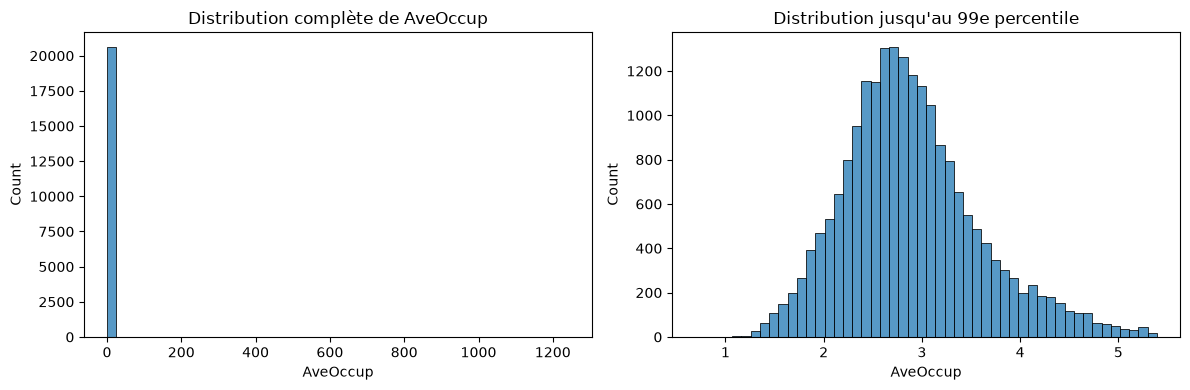

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcul du 99e percentile
seuil_99 = df["AveOccup"].quantile(0.99)

# Création de deux graphiques
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Graphique 1 : toutes les observations
sns.histplot(
    data=df,
    x="AveOccup",
    bins=50,
    ax=axes[0]
)
axes[0].set_title("Distribution complète de AveOccup")

# Graphique 2 : zoom sur les valeurs <= 99e percentile
sns.histplot(
    data=df[df["AveOccup"] <= seuil_99],
    x="AveOccup",
    bins=50,
    ax=axes[1]
)
axes[1].set_title("Distribution jusqu'au 99e percentile")

plt.tight_layout()
plt.show()

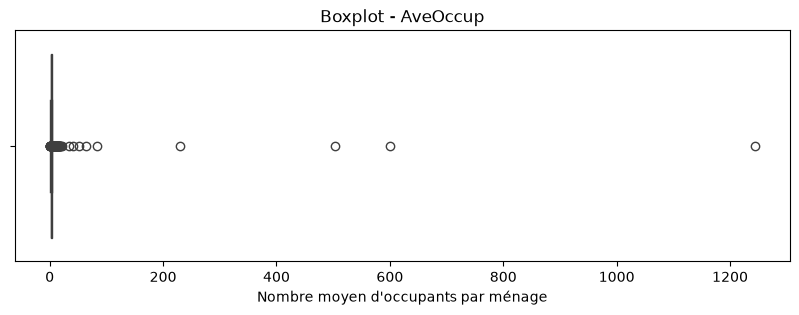

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisation des valeurs extrêmes
plt.figure(figsize=(10, 3))

sns.boxplot(x=df["AveOccup"])

plt.title("Boxplot - AveOccup")
plt.xlabel("Nombre moyen d'occupants par ménage")
plt.show()

In [12]:
# 1. Calculer les quartiles
Q1 = df["AveOccup"].quantile(0.25)
Q3 = df["AveOccup"].quantile(0.75)

# 2. Calculer l'écart interquartile
IQR = Q3 - Q1

# 3. Définir les bornes
borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

# 4. Identifier les observations atypiques
masque_outliers = (
    (df["AveOccup"] < borne_inf) |
    (df["AveOccup"] > borne_sup)
)

# 5. Compter les observations atypiques
nb_outliers = masque_outliers.sum()
pourcentage = nb_outliers / len(df) * 100

print(f"Borne inférieure : {borne_inf:.3f}")
print(f"Borne supérieure : {borne_sup:.3f}")
print(f"Nombre d'outliers : {nb_outliers}")
print(f"Pourcentage : {pourcentage:.2f}%")

Borne inférieure : 1.151
Borne supérieure : 4.561
Nombre d'outliers : 711
Pourcentage : 3.44%


In [13]:
# Sélectionner les observations atypiques
df_outliers = df.loc[
    masque_outliers,
    ["AveOccup", "Population", "AveRooms",
     "AveBedrms", "MedHouseVal"]
]

# Afficher les 10 plus grandes valeurs de AveOccup
display(
    df_outliers.sort_values(
        by="AveOccup",
        ascending=False
    ).head(10)
)

,AveOccup,Population,AveRooms,AveBedrms,MedHouseVal
19006,1243.333333,7460.0,3.166667,0.833333,1.37500
3364,599.714286,4198.0,5.142857,1.142857,0.67500
16669,502.461538,6532.0,9.076923,1.307692,3.50000
13034,230.172414,6675.0,8.275862,1.517241,2.25000
9172,83.171429,8733.0,5.123810,0.933333,1.54600
12104,63.750000,1275.0,7.600000,0.950000,1.62500
16420,51.400000,1542.0,5.366667,0.900000,1.62500
8874,41.214286,1154.0,7.285714,1.214286,5.00001
13366,33.952941,2886.0,5.258824,1.117647,1.83300
5986,21.333333,2688.0,4.500000,1.206349,2.12500


In [14]:
# Sélectionner les observations atypiques
df_outliers = df.loc[
    masque_outliers,
    ["AveOccup", "Population", "AveRooms",
     "AveBedrms", "MedHouseVal"]
]

# Afficher les 10 plus grandes valeurs de AveOccup
display(
    df_outliers.sort_values(
        by="AveOccup",
        ascending=False
    ).head(10)
)

,AveOccup,Population,AveRooms,AveBedrms,MedHouseVal
19006,1243.333333,7460.0,3.166667,0.833333,1.37500
3364,599.714286,4198.0,5.142857,1.142857,0.67500
16669,502.461538,6532.0,9.076923,1.307692,3.50000
13034,230.172414,6675.0,8.275862,1.517241,2.25000
9172,83.171429,8733.0,5.123810,0.933333,1.54600
12104,63.750000,1275.0,7.600000,0.950000,1.62500
16420,51.400000,1542.0,5.366667,0.900000,1.62500
8874,41.214286,1154.0,7.285714,1.214286,5.00001
13366,33.952941,2886.0,5.258824,1.117647,1.83300
5986,21.333333,2688.0,4.500000,1.206349,2.12500


In [15]:
variables = [
    "AveRooms",
    "AveBedrms",
    "AveOccup",
    "Population"
]

resultats = []

for variable in variables:

    Q1 = df[variable].quantile(0.25)
    Q3 = df[variable].quantile(0.75)

    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    masque = (
        (df[variable] < borne_inf) |
        (df[variable] > borne_sup)
    )

    nb = masque.sum()
    pourcentage = nb / len(df) * 100

    resultats.append({
        "Variable": variable,
        "Borne_inf": borne_inf,
        "Borne_sup": borne_sup,
        "Nb_outliers": nb,
        "Pourcentage": pourcentage
    })

bilan_outliers = pd.DataFrame(resultats)

display(bilan_outliers.round(2))

,Variable,Borne_inf,Borne_sup,Nb_outliers,Pourcentage
0,AveRooms,2.02,8.47,511,2.48
1,AveBedrms,0.87,1.24,1424,6.90
2,AveOccup,1.15,4.56,711,3.44
3,Population,-620.00,3132.00,1196,5.79


Valeur maximale : 5.00001
Nombre d'observations au maximum : 965
Pourcentage : 4.68%


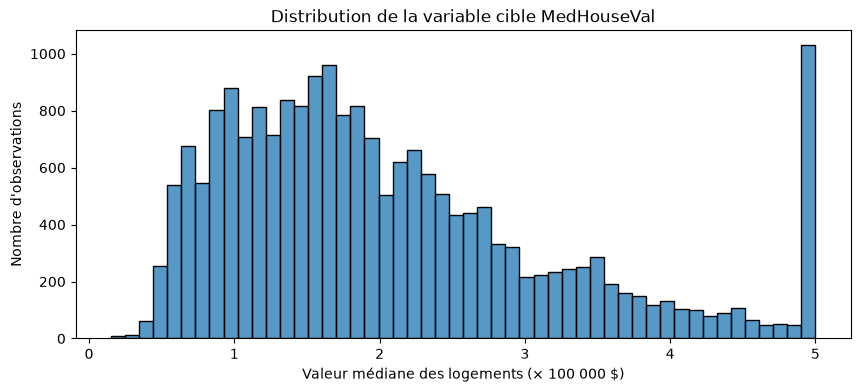

In [16]:
# 1. Analyser la variable cible
cible = df["MedHouseVal"]

# 2. Identifier le maximum
valeur_max = cible.max()

# 3. Compter les observations au maximum
nb_max = (cible == valeur_max).sum()

# 4. Calculer leur pourcentage
pourcentage_max = nb_max / len(cible) * 100

print(f"Valeur maximale : {valeur_max:.5f}")
print(f"Nombre d'observations au maximum : {nb_max}")
print(f"Pourcentage : {pourcentage_max:.2f}%")

# 5. Visualiser la distribution
plt.figure(figsize=(10, 4))

sns.histplot(
    data=df,
    x="MedHouseVal",
    bins=50
)

plt.title("Distribution de la variable cible MedHouseVal")
plt.xlabel("Valeur médiane des logements (× 100 000 $)")
plt.ylabel("Nombre d'observations")

plt.show()

In [17]:
from sklearn.model_selection import train_test_split

# 1. Réserver 15 % pour le test final
train_val_df, test_df = train_test_split(
    df,
    test_size=0.15,
    random_state=42
)

# 2. Séparer les 85 % restants
# 15/85 permet d'obtenir 15 % du dataset initial
train_df, val_df = train_test_split(
    train_val_df,
    test_size=15/85,
    random_state=42
)

# 3. Vérifier les dimensions
print("Train :", train_df.shape)
print("Validation :", val_df.shape)
print("Test :", test_df.shape)

Train : (14448, 9)
Validation : (3096, 9)
Test : (3096, 9)


In [18]:
# 1. Calculer la matrice des corrélations de Pearson
correlations = train_df.corr(method="pearson")

# 2. Afficher les corrélations avec notre cible
correlations_cible = correlations["MedHouseVal"].drop("MedHouseVal")

# 3. Classer les corrélations par ordre décroissant
display(correlations_cible.sort_values(ascending=False))

MedInc        0.688071
AveRooms      0.141638
HouseAge      0.099772
Population   -0.021725
AveOccup     -0.026397
AveBedrms    -0.045206
Longitude    -0.048577
Latitude     -0.143360
Name: MedHouseVal, dtype: float64

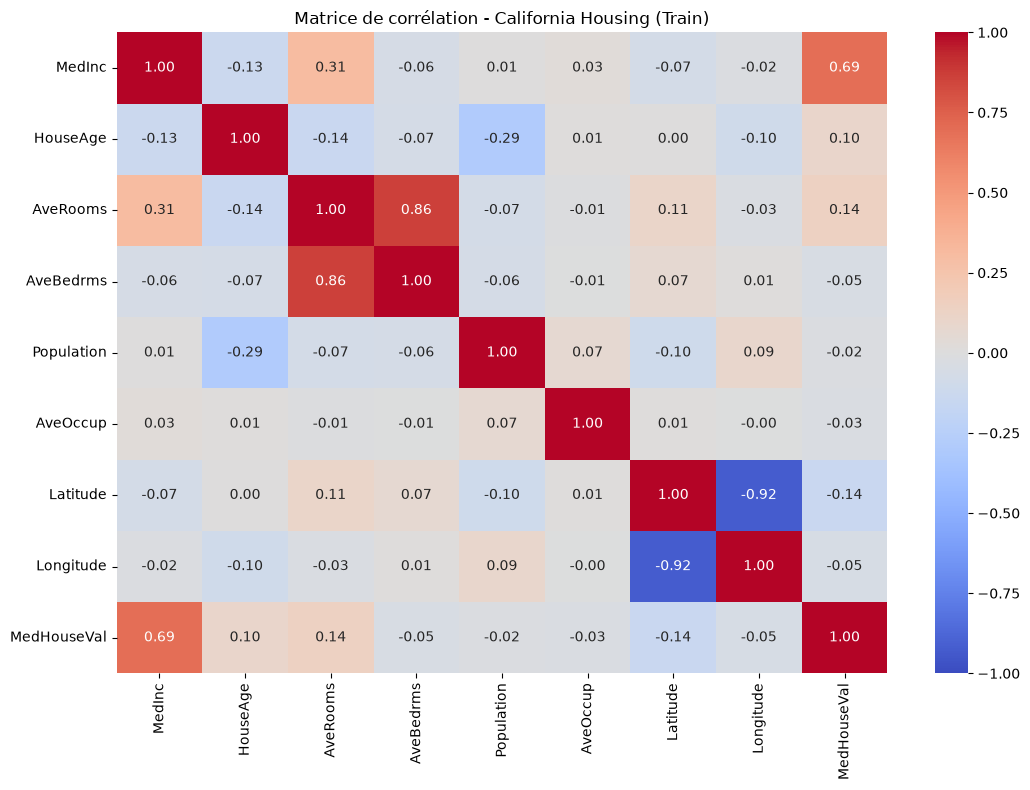

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Matrice de corrélation sur les données d'entraînement
matrice_corr = train_df.corr(method="pearson")

# Création de la heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    matrice_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Matrice de corrélation - California Housing (Train)")
plt.tight_layout()
plt.show()

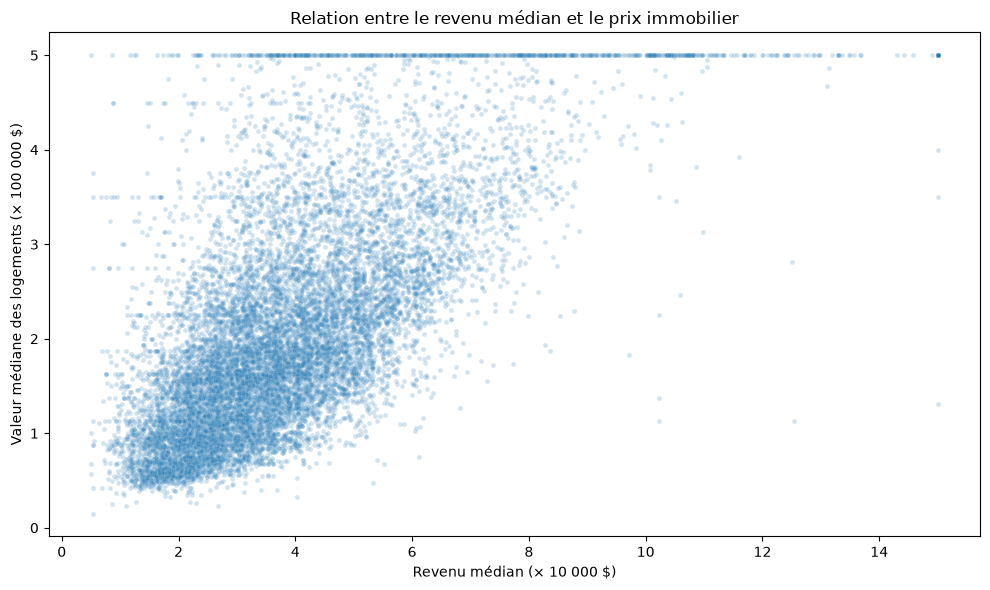

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=train_df,
    x="MedInc",
    y="MedHouseVal",
    alpha=0.2,
    s=12
)

plt.title("Relation entre le revenu médian et le prix immobilier")
plt.xlabel("Revenu médian (× 10 000 $)")
plt.ylabel("Valeur médiane des logements (× 100 000 $)")

plt.tight_layout()
plt.show()

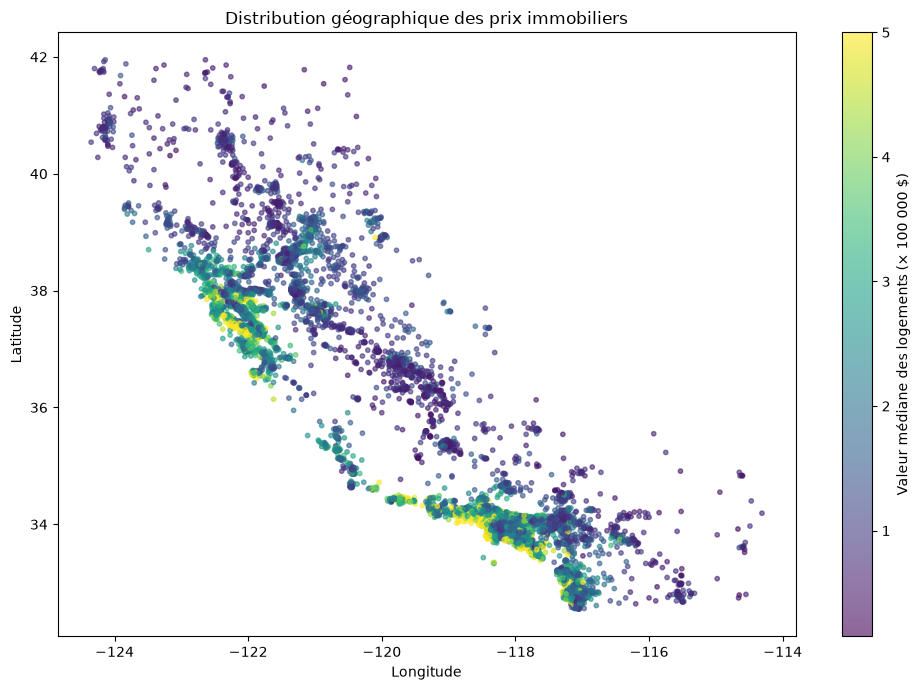

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    x=train_df["Longitude"],
    y=train_df["Latitude"],
    c=train_df["MedHouseVal"],
    cmap="viridis",
    s=10,
    alpha=0.6
)

plt.colorbar(
    scatter,
    label="Valeur médiane des logements (× 100 000 $)"
)

plt.title("Distribution géographique des prix immobiliers")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.show()

In [22]:
# Définir la variable cible
target = "MedHouseVal"

# Données d'entraînement
X_train = train_df.drop(columns=[target])
y_train = train_df[target]

# Données de validation
X_val = val_df.drop(columns=[target])
y_val = val_df[target]

# Données de test
X_test = test_df.drop(columns=[target])
y_test = test_df[target]

# Vérification des dimensions
print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("X_val :", X_val.shape)
print("y_val :", y_val.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train : (14448, 8)
y_train : (14448,)
X_val : (3096, 8)
y_val : (3096,)
X_test : (3096, 8)
y_test : (3096,)


In [23]:
from pathlib import Path

# Localiser le dossier du projet
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Créer le dossier des partitions
splits_dir = project_dir / "data" / "splits"
splits_dir.mkdir(parents=True, exist_ok=True)

# Sauvegarder les ensembles
train_df.to_csv(splits_dir / "train.csv", index=False)
val_df.to_csv(splits_dir / "validation.csv", index=False)
test_df.to_csv(splits_dir / "test.csv", index=False)

print("Partitions sauvegardées :")
print("Train :", train_df.shape)
print("Validation :", val_df.shape)
print("Test :", test_df.shape)

Partitions sauvegardées :
Train : (14448, 9)
Validation : (3096, 9)
Test : (3096, 9)
